# Supplementary material — effect of fibre dimensions

### Common libraries and `mpl` settings

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import ovito
from ovito.io import import_file
from ovito.vis import TachyonRenderer, Viewport
import gzip
from itertools import islice
from collections import deque
from tempfile import TemporaryDirectory
from ovito.modifiers import (
    ExpressionSelectionModifier,
    DeleteSelectedModifier,
    ClusterAnalysisModifier,
)

MM = 1.0 / 25.4
Tm = 4996


mpl.rcParams.update(
    {
        "text.usetex": False,
        "font.family": "serif",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "mathtext.sf": "Times New Roman",
        "mathtext.fallback": "stix",
        "font.size": 8,
        "axes.labelsize": 8,
        "axes.titlesize": 8,
        "legend.fontsize": 8,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "axes.linewidth": 1.0,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "legend.frameon": False,
        "axes.grid": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

results_folder = Path.cwd().parent / "single_fiber" / "heat" / "results" / "TMB"

out_folder = Path.cwd() / "figures"
out_folder.mkdir(exist_ok=True)

pp = Path("pp_data")
pp.mkdir(exist_ok=True)
snapshot_folder = out_folder / "size_geometry"
snapshot_folder.mkdir(exist_ok=True)

alphas = [25, 100, 400, 800]
cases = ["phi006", "phi006_l144", "phi006_r024"]
states = ["he0", "he2"]
a0 = 3.1442213
sizes = dict(zip(cases, [(32, 63), (32, 144), (48, 63)]))
labels = dict(zip(cases, ["Reference", "Longer", "Wider"]))
colors = dict(zip(cases, ["tab:blue", "tab:green", "tab:orange"]))
styles = {"he0": "--", "he2": "-"}
quantities = ["tc", "Tc_Tm", "eps_c"]


def read_break(run):
    stop = pd.read_csv(run / "heat_off.txt", sep=r"\s+").iloc[0]
    return stop.time_ps, stop.T_cluster


seeds_25 = dict(zip(cases, [43, 43, 42]))
runs = {
    (alpha, case): results_folder
    / case
    / f"s{seeds_25[case] if alpha == 25 else 44}"
    / "he2"
    / f"alpha_{alpha:.1f}"
    for alpha in [25, 400]
    for case in cases
}

## Data preparation from MD

### Connectivity-loss metrics and cluster evolution

In [2]:
rows, traces = [], []

for case in cases:
    seeds = range(42, 52) if case == "phi006" else range(42, 45)
    for state in states:
        for alpha in alphas:
            for seed in seeds:
                run = results_folder / case / f"s{seed}" / state / f"alpha_{alpha:.1f}"
                tc, Tc = read_break(run)
                N0 = pd.read_csv(
                    run / "heat.txt", sep=r"\s+", usecols=["NW_box"], nrows=1
                ).NW_box.iloc[0]
                d = pd.read_csv(
                    run / "structure.txt",
                    sep=r"\s+",
                    usecols=["time_ps", "Nlargest", "Nheat", "T_cluster"],
                )
                d = (
                    d[d.time_ps <= tc + 1e-6]
                    .sort_values("time_ps")
                    .drop_duplicates("time_ps", keep="last")
                )
                eps_c = (
                    3
                    * 8.617333262e-5
                    * alpha
                    * np.sum(np.diff(d.time_ps) * d.Nheat.to_numpy()[:-1])
                    / N0
                )
                rows.append((case, state, alpha, seed, tc, Tc, Tc / Tm, eps_c))
                d = d[d.time_ps <= tc].copy()
                d["f_LCC"] = d.Nlargest / N0
                d["f_heat"] = d.Nheat / N0
                d["t_tc"] = d.time_ps / tc
                traces.append(d.assign(case=case, state=state, alpha=alpha, seed=seed))

metrics = pd.DataFrame(
    rows, columns=["case", "state", "alpha", "seed", "tc", "Tc", "Tc_Tm", "eps_c"]
)
traces = pd.concat(traces, ignore_index=True)
metrics.to_csv(pp / "size_metrics.csv", index=False)
traces.to_csv(pp / "size_traces.csv.gz", index=False)

### Connectivity-loss statistics

In [3]:
metrics = pd.read_csv(pp / "size_metrics.csv")
summary = metrics.groupby(["state", "alpha", "case"], as_index=False).agg(
    tc_mean=("tc", "mean"),
    tc_std=("tc", "std"),
    Tc_Tm_mean=("Tc_Tm", "mean"),
    Tc_Tm_std=("Tc_Tm", "std"),
    eps_c_mean=("eps_c", "mean"),
    eps_c_std=("eps_c", "std"),
)
summary.to_csv(pp / "size_summary.csv", index=False)

### Axial W profiles

In [4]:
profiles = {}
for alpha in [25, 400]:
    for case in cases:
        run = runs[alpha, case]
        tc, _ = read_break(run)
        print(case, alpha, f"tc = {tc:g} ps", flush=True)
        with TemporaryDirectory() as tmp:
            sampled = Path(tmp) / "sampled.lammpstrj"
            last_t = -np.inf
            with (
                gzip.open(run / "dump_mech.lammpstrj.gz", "rb") as f,
                sampled.open("wb") as out,
            ):
                while line := f.readline():
                    header = [line] + [f.readline() for _ in range(8)]
                    t, n = int(header[1]) * 0.001, int(header[3])
                    if (alpha == 25 and t >= tc) or t > tc + 1e-8:
                        break
                    dt_sample = 10 if alpha == 25 else (2 if t < 0.8 * tc else 0.5)
                    if t - last_t >= dt_sample - 1e-8 or tc - t <= 0.250001:
                        out.writelines(header)
                        out.writelines(islice(f, n))
                        last_t = t
                    else:
                        deque(islice(f, n), maxlen=0)

            p = import_file(str(sampled))
            p.modifiers.append(
                ExpressionSelectionModifier(expression="ParticleType != 1")
            )
            p.modifiers.append(DeleteSelectedModifier())
            p.modifiers.append(ClusterAnalysisModifier(cutoff=3.7, sort_by_size=True))
            times, eta = [], []
            for frame in range(p.source.num_frames):
                d = p.compute(frame)
                mask = np.asarray(d.particles["Cluster"]) == 1
                pos = np.asarray(d.particles.positions)[mask]
                L, z0 = d.cell[2, 2], d.cell[2, 3]
                edges = np.linspace(0, L, round(L / 10) + 1)
                z = (pos[:, 2] - z0) % L
                times.append(0.001 * d.attributes["Timestep"])
                eta.append(np.histogram(z, bins=edges)[0] / np.diff(edges))
            eta = np.asarray(eta)
            v = dict(
                t=np.asarray(times),
                tc=tc,
                seed=int(run.parents[1].name[1:]),
                z=0.05 * (edges[:-1] + edges[1:]),
                eta=eta / eta[0].mean(),
            )
            profiles[alpha, case] = v
            print(f"Processed frames: {len(times)}", flush=True)
            del p

np.savez_compressed(
    pp / "size_profiles.npz",
    **{
        f"a{alpha}_{case}_{key}": value
        for (alpha, case), v in profiles.items()
        for key, value in v.items()
    },
)

phi006 25 tc = 1453 ps
Processed frames: 146
phi006_l144 25 tc = 1255 ps
Processed frames: 126
phi006_r024 25 tc = 2002.5 ps
Processed frames: 201
phi006 400 tc = 65.5 ps
Processed frames: 55
phi006_l144 400 tc = 63.5 ps
Processed frames: 39
phi006_r024 400 tc = 69 ps
Processed frames: 42


### Initial geometries

In [5]:
prepared_folder = Path.cwd().parent / "single_fiber" / "prepare" / "prepared" / "TMB"

renderer = TachyonRenderer(
    ambient_occlusion=True, shadows=True, direct_light_intensity=0.85
)


def cut_w(frame, data):
    pos = np.asarray(data.particles.positions)
    types = np.asarray(data.particles["Particle Type"])
    x0 = 0.5 * (pos[types == 1, 0].min() + pos[types == 1, 0].max())
    data.particles_.delete_elements(pos[:, 0] < x0)


for pipeline in list(ovito.scene.pipelines):
    pipeline.remove_from_scene()

for case in cases:
    p = import_file(str(prepared_folder / case / "s44" / "he2" / "data.300K"))
    data = p.source.data
    data.cell_.vis.enabled = False

    types = data.particles_.particle_types_
    types.type_by_id_(1).color = (0.78, 0.80, 0.82)
    types.type_by_id_(1).radius = 1.30
    types.type_by_id_(2).color = (0.78, 0.34, 0.55)
    types.type_by_id_(2).radius = 1.10

    d = p.compute()
    pos = np.asarray(d.particles.positions)[
        np.asarray(d.particles["Particle Type"]) == 1
    ]
    center = 0.5 * (pos.min(axis=0) + pos.max(axis=0))

    p.modifiers.append(cut_w)

    vp = Viewport(type=Viewport.Type.Ortho)
    vp.camera_dir = (1, 0, 0)
    vp.camera_up = (0, 1, 0)
    vp.camera_pos = tuple(center - np.array([600, 0, 0]))
    vp.fov = 110

    p.add_to_scene()
    vp.render_image(
        filename=str(snapshot_folder / f"{case}.png"),
        size=(1800, 700),
        background=(1, 1, 1),
        renderer=renderer,
    )
    p.remove_from_scene()

    del p

## Figures and table

### Data loading

In [6]:
metrics = pd.read_csv(pp / "size_metrics.csv")
traces = pd.read_csv(pp / "size_traces.csv.gz")
summary = pd.read_csv(pp / "size_summary.csv")

with np.load(pp / "size_profiles.npz") as saved:
    profiles = {
        (a, c): {k: saved[f"a{a}_{c}_{k}"] for k in ("t", "tc", "seed", "z", "eta")}
        for a in [25, 400]
        for c in cases
    }

### Figure S1

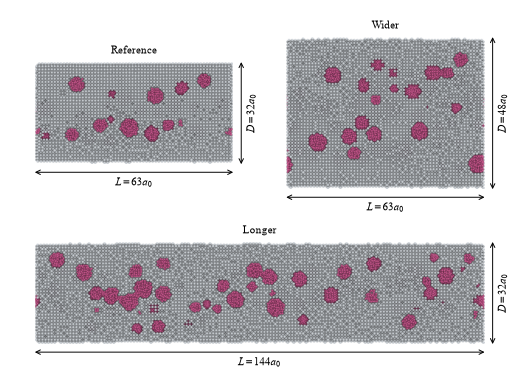

In [7]:
imgs = {}

for case in cases:
    img = plt.imread(snapshot_folder / f"{case}.png")
    yy, xx = np.where(np.any(img[..., :3] < 0.98, axis=2))
    imgs[case] = img[yy.min() : yy.max() + 1, xx.min() : xx.max() + 1]

geom = {
    "phi006": ("Reference", 32, 63),
    "phi006_r024": ("Wider", 48, 63),
    "phi006_l144": ("Longer", 32, 144),
}

h0, w0 = imgs["phi006"].shape[:2]
h1, w1 = imgs["phi006_r024"].shape[:2]
h2, w2 = imgs["phi006_l144"].shape[:2]

left_margin = 80
right_margin = 120
bottom_margin = 90
top_margin = 90
vgap = 170

W = w2 + left_margin + right_margin
H = h2 + max(h0, h1) + vgap + bottom_margin + top_margin

x2 = left_margin
y2 = bottom_margin

x0 = x2
x1 = x2 + w2 - w1
y_top = y2 + h2 + vgap

positions = {
    "phi006": (x0, y_top + (max(h0, h1) - h0) / 2),
    "phi006_r024": (x1, y_top + (max(h0, h1) - h1) / 2),
    "phi006_l144": (x2, y2),
}

fig, ax = plt.subplots(figsize=(130 * MM, 130 * MM * H / W))
fig.subplots_adjust(left=0, right=1, bottom=0, top=1)

for case, (x, y) in positions.items():
    img = imgs[case]
    h, w = img.shape[:2]
    label, D, L = geom[case]

    ax.imshow(img, extent=(x, x + w, y, y + h))

    ax.text(x + 0.5 * w, y + h + 20, label, ha="center", va="bottom")

    y_dim = y - 26
    ax.annotate(
        "",
        (x + w, y_dim),
        (x, y_dim),
        arrowprops=dict(arrowstyle="<->", lw=0.7, shrinkA=0, shrinkB=0),
    )
    ax.text(x + 0.5 * w, y_dim - 18, rf"$L={L}a_0$", ha="center", va="top")

    x_dim = x + w + 26
    ax.annotate(
        "",
        (x_dim, y + h),
        (x_dim, y),
        arrowprops=dict(arrowstyle="<->", lw=0.7, shrinkA=0, shrinkB=0),
    )
    ax.text(
        x_dim + 18, y + 0.5 * h, rf"$D={D}a_0$", rotation=90, ha="left", va="center"
    )

ax.set_xlim(0, W)
ax.set_ylim(0, H)
ax.set_aspect("equal")
ax.axis("off")


fig.savefig(out_folder / "supplementary_geometry.png", dpi=600)
plt.show()

### Figure S2

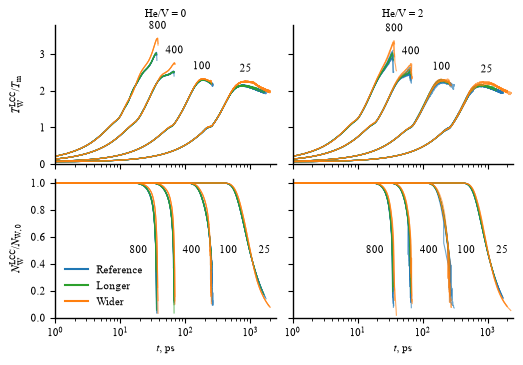

In [8]:
fig, axes = plt.subplots(
    2, 2, figsize=(130 * MM, 90 * MM), sharex=True, sharey="row", layout="constrained"
)

for j, state in enumerate(states):
    for case in cases:
        d = traces[(traces.state == state) & (traces.case == case)]
        for (alpha, seed), g in d.groupby(["alpha", "seed"]):
            g = g.sort_values("time_ps")
            g = g[g.time_ps > 0]
            axes[0, j].plot(
                g.time_ps, g.T_cluster / Tm, color=colors[case], lw=0.8, alpha=0.65
            )
            axes[1, j].plot(g.time_ps, g.f_LCC, color=colors[case], lw=0.8, alpha=0.65)

    axes[0, j].set_title(f"He/V = {state[-1]}")
    axes[1, j].set(
        xlabel=r"$t$, ps",
        xscale="log",
        xlim=(1, 1.1 * metrics.tc.max()),
        ylim=(0, 1.03),
    )

    for alpha in alphas:
        d = traces[(traces.state == state) & (traces.alpha == alpha)]
        r = d.loc[d.T_cluster.idxmax()]

        axes[0, j].annotate(
            str(alpha),
            (r.time_ps, r.T_cluster / Tm),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
        )

        times = [
            g.loc[(g.f_LCC - 0.5).abs().idxmin(), "time_ps"]
            for _, g in d.groupby(["case", "seed"])
        ]

        left = alpha == 800
        t_label = min(times) if left else max(times)

        axes[1, j].annotate(
            str(alpha),
            (t_label, 0.5),
            xytext=(-6 if left else 6, 0),
            textcoords="offset points",
            ha="right" if left else "left",
            va="center",
        )

axes[0, 0].set_ylabel(r"$T_\mathrm{W}^\mathrm{LCC}/T_\mathrm{m}$")
axes[0, 0].set_ylim(0, max(3.6, traces.T_cluster.max() / Tm + 0.35))
axes[1, 0].set_ylabel(r"$N_\mathrm{W}^\mathrm{LCC}/N_{\mathrm{W},0}$")
axes[1, 0].legend(
    handles=[Line2D([], [], color=colors[c], label=labels[c]) for c in cases],
    loc="lower left",
)

fig.align_ylabels()
fig.savefig(out_folder / "size_dynamics.pdf")
plt.show()

### Figure S3

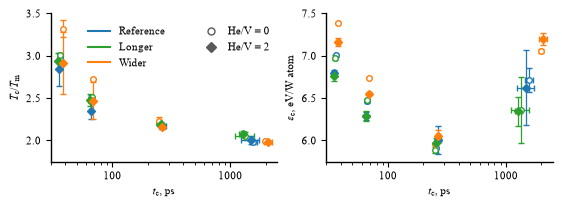

In [9]:
markers = {"he0": "o", "he2": "D"}

fig, axes = plt.subplots(
    1, 2, figsize=(140 * MM, 50 * MM), sharex=True, layout="constrained"
)

for r in summary.itertuples(index=False):
    state, case = r.state, r.case
    color = colors[case]

    axes[0].errorbar(
        r.tc_mean,
        r.Tc_Tm_mean,
        xerr=r.tc_std,
        yerr=r.Tc_Tm_std,
        fmt=markers[state],
        ms=4,
        mfc="white" if state == "he0" else color,
        mec=color,
        ecolor=color,
        elinewidth=0.9,
        capsize=2,
        zorder=3,
    )

    axes[1].errorbar(
        r.tc_mean,
        r.eps_c_mean,
        xerr=r.tc_std,
        yerr=r.eps_c_std,
        fmt=markers[state],
        ms=4,
        mfc="white" if state == "he0" else color,
        mec=color,
        ecolor=color,
        elinewidth=0.9,
        capsize=2,
        zorder=3,
    )

for ax in axes:
    ax.set_xscale("log")
    ax.set_xlim(30, 2500)
    ax.set_xticks([100, 1000], labels=["100", "1000"])
    ax.set_xlabel(r"$t_\mathrm{c}$, ps")

axes[0].set_ylabel(r"$T_\mathrm{c}/T_\mathrm{m}$")
axes[0].set_ylim(1.75, 3.5)
axes[1].set_ylabel(r"$\varepsilon_\mathrm{c}$, eV/W atom")
axes[1].set_ylim(5.75, 7.5)

geom_handles = [Line2D([], [], color=colors[c], label=labels[c]) for c in cases]

state_handles = [
    Line2D(
        [],
        [],
        marker=markers[s],
        ls="none",
        ms=5,
        mfc="white" if s == "he0" else "0.35",
        mec="0.35",
        label=f"He/V = {s[-1]}",
    )
    for s in states
]

leg1 = axes[0].legend(
    handles=geom_handles,
    loc="upper left",
    bbox_to_anchor=(0.12, 0.98),
    frameon=False,
    ncol=1,
    handlelength=2.0,
)
axes[0].add_artist(leg1)

axes[0].legend(
    handles=state_handles,
    loc="upper left",
    bbox_to_anchor=(0.63, 0.98),
    frameon=False,
    ncol=1,
    handlelength=1.4,
)

fig.savefig(out_folder / "size_connectivity.pdf")
plt.show()

### Figure S4

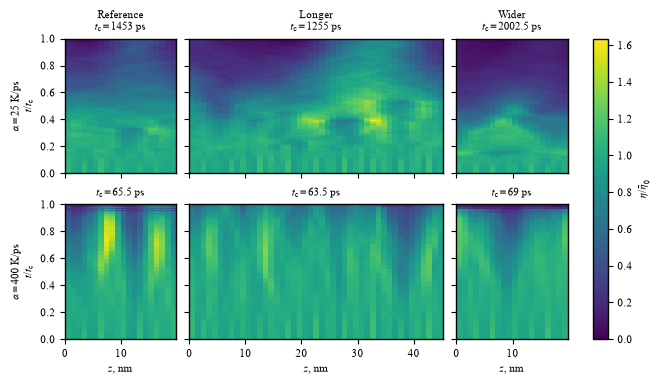

In [10]:
fig_profiles, axes = plt.subplots(
    2,
    3,
    figsize=(165 * MM, 95 * MM),
    sharey=True,
    gridspec_kw={"width_ratios": [63, 144, 63]},
    layout="compressed",
)
vmax = max(profiles[alpha, case]["eta"].max() for alpha in [25, 400] for case in cases)

for i, alpha in enumerate([25, 400]):
    for j, case in enumerate(cases):
        ax = axes[i, j]
        v = profiles[alpha, case]
        im = ax.pcolormesh(
            v["z"],
            v["t"] / v["tc"],
            v["eta"],
            shading="auto",
            cmap="viridis",
            vmin=0,
            vmax=vmax,
            rasterized=True,
        )
        title = rf"$t_\mathrm{{c}}={float(v['tc']):g}$ ps"
        ax.set_title(labels[case] + "\n" + title if i == 0 else title)
        ax.set_ylim(0, 1)
        if i == 1:
            ax.set_xlabel(r"$z$, nm")
        else:
            ax.tick_params(labelbottom=False)
        if j == 0:
            ax.set_ylabel(rf"$\alpha={alpha}$ K/ps" + "\n" + r"$t/t_\mathrm{c}$")
        for spine in ax.spines.values():
            spine.set_visible(True)

fig_profiles.colorbar(im, ax=axes, label=r"$\eta/\bar{\eta}_0$")
fig_profiles.savefig(out_folder / "size_profiles.png", dpi=600)
plt.show()